In [13]:
from pathlib import Path
import logging
import os
import warnings

import scanpy as sc
import torch

from utils import (
    build_args_known,
    fix_rpy2_encoding,
    load_best_configs,
    train_single_sample,
)
from process.preprocess import preprocess, construct_interaction, get_feature
from process.function import Function

In [14]:
os.environ['R_ENCODING'] = 'UTF-8'
os.environ['LC_ALL'] = 'C'
os.environ['LANG'] = 'en_US.UTF-8'

fix_rpy2_encoding()
warnings.filterwarnings('ignore', category=UnicodeWarning)
logging.basicConfig(format="%(asctime)s - %(levelname)s - %(message)s", level=logging.INFO)

In [15]:
args = build_args_known([])
args.dataset = 'DLPFC'
args.use_cfg = True
args = load_best_configs(args)

args.sample = ['151673']
args.seeds = [46]
args.alpha_l= 3
args.eval_interval = 10
args.fused_contrast_loss_weight = 0.0
args.cluster_rep_mode = 'view_pca_concat'
args.cluster_fused_weight = 1.0
args.cluster_struct_weight = 1.0
args.cluster_sem_weight = 0.5
args.cluster_fused_pca_dim = 27
args.cluster_struct_pca_dim = 6
args.cluster_sem_pca_dim = 3

print(f"Loaded configs/{args.dataset}.yaml")
print(
    "Mainline: sample={}, seeds={}, eval_interval={}, cluster={}, pca_dims={}/{}/{}".format(
        args.sample,
        args.seeds,
        args.eval_interval,
        args.cluster_rep_mode,
        args.cluster_fused_pca_dim,
        args.cluster_struct_pca_dim,
        args.cluster_sem_pca_dim,
    )
)

2026-10-16 15:38:07,529 - INFO - ----- Using best configs from configs\DLPFC.yaml -----


Loaded configs/DLPFC.yaml
Mainline: sample=['151673'], seeds=[46], eval_interval=10, cluster=view_pca_concat, pca_dims=27/6/3


In [16]:
import yaml

config_path = f"configs/{args.dataset}.yaml"
with open(config_path, 'r', encoding='utf-8') as f:
    config_content = yaml.load(f, yaml.FullLoader)

print(f"Configuration from {config_path}:")
print("-" * 50)
for key, value in config_content.items():
    print(f"{key:28s}: {value}")
print("-" * 50)

Configuration from configs/DLPFC.yaml:
--------------------------------------------------
seeds                       : [46]
--------------------------------------------------


In [17]:
sample = args.sample[0]
dataset = args.dataset

file_fold = Path("results") / dataset / sample
file_fold.mkdir(parents=True, exist_ok=True)
function = Function(sample=sample, datatype=dataset)
adata = function.loadData()
adata.var_names_make_unique()

print("Data loaded successfully")
print(f"Number of spots: {adata.n_obs}")
print(f"Number of genes: {adata.n_vars}")
print(f"Data shape: {adata.shape}")
adata

d:\Users\15696\anaconda3\envs\MAEST\lib\site-packages\anndata\_core\anndata.py:1908: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
d:\Users\15696\anaconda3\envs\MAEST\lib\site-packages\anndata\_core\anndata.py:1908: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


[Labels] DLPFC/151673: 7 annotated classes
Data loaded successfully
Number of spots: 3639
Number of genes: 33538
Data shape: (3639, 33538)


AnnData object with n_obs × n_vars = 3639 × 33538
    obs: 'in_tissue', 'array_row', 'array_col', 'ground_truth'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatial', 'has_ground_truth'
    obsm: 'spatial'

In [18]:
print("Spatial coordinates available:", 'spatial' in adata.obsm.keys())
if 'spatial' in adata.obsm.keys():
    print(f"Spatial coordinates shape: {adata.obsm['spatial'].shape}")

Spatial coordinates available: True
Spatial coordinates shape: (3639, 2)


In [19]:
print("Step 1: preprocessing data")
preprocess(adata, sample=sample)
print(f"Selected {adata.var['highly_variable'].sum()} highly variable genes")

print("\nStep 2: constructing spatial graph")
if 'adj' not in adata.obsm.keys():
    u, v = construct_interaction(adata)
    print(f"Spatial graph constructed with {len(u)} edges")
else:
    adj = adata.obsm['adj']
    u, v = adj.nonzero()
    print(f"Using existing spatial graph with {len(u)} edges")

print("\nStep 3: extracting features")
if 'feat' not in adata.obsm.keys():
    get_feature(adata)
print(f"Feature matrix shape: {adata.obsm['feat'].shape}")

print("\nData preprocessing completed")
print(f"Final data shape: {adata.shape}")

Step 1: preprocessing data
Selected 3000 highly variable genes

Step 2: constructing spatial graph
Spatial graph constructed with 10917 edges

Step 3: extracting features
Feature matrix shape: (3639, 3000)

Data preprocessing completed
Final data shape: (3639, 33538)


In [20]:
adata

AnnData object with n_obs × n_vars = 3639 × 33538
    obs: 'in_tissue', 'array_row', 'array_col', 'ground_truth'
    var: 'gene_ids', 'feature_types', 'genome', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'mean', 'std'
    uns: 'spatial', 'has_ground_truth', 'hvg', 'log1p'
    obsm: 'spatial', 'distance_matrix', 'graph_neigh', 'adj', 'feat'

In [22]:
device = args.device if args.device >= 0 else "cpu"
seeds = args.seeds if isinstance(args.seeds, list) else [args.seeds]
n_clusters = 7
logger = None

print(f"Device: {device}")
print(f"Training sample: {sample}")
print(f"Random seeds: {seeds}")
print(f"Max epochs: {args.max_epoch}")
print(f"Learning rate: {args.lr}")
print(f"Hidden units: {args.num_hidden}")
print(f"Cluster representation: {args.cluster_rep_mode}")
print(f"PCA budget: {args.cluster_fused_pca_dim}/{args.cluster_struct_pca_dim}/{args.cluster_sem_pca_dim}")

best_ari_overall = -1
final_adata_overall = None
function_overall = None

for seed in seeds:
    print(f"\n--- Training with seed: {seed} ---")
    best_ari, final_adata, function = train_single_sample(
        args=args,
        sample=sample,
        seed=seed,
        dataset=dataset,
        device=device,
        logger=logger,
        adata=adata,
        u=u,
        v=v,
        n_clusters=n_clusters,
    )
    print(f"Seed {seed} -> Best ARI: {best_ari:.4f}")

    if best_ari > best_ari_overall:
        best_ari_overall = best_ari
        final_adata_overall = final_adata
        function_overall = function

final_adata = final_adata_overall
function = function_overall

print("\nTraining completed")
print(f"Best ARI across seeds: {best_ari_overall:.4f}")

if logger is not None:
    logger.finish()

Device: 0
Training sample: 151673
Random seeds: [46]
Max epochs: 900
Learning rate: 0.001
Hidden units: 1024
Cluster representation: view_pca_concat
PCA budget: 27/6/3

--- Training with seed: 46 ---


2026-10-16 15:39:36,173 - INFO - start training..


[SemanticView] loaded local evidence: cache\llm_embeddings\DLPFC_151673_gpt-5.5_proto_disc_v2_soft_codex_proto160_k10_evidence.npy | shape=(3639, 10)


2026-10-16 15:39:41,875 - INFO - Use fixed-horizon cosine scheduler
# Epoch 0: loss=1.0135 rec=0.9923 align=1.0187 contrast=5.9267 gate=0.5000 prune=382/10917(3.50%) sem_edges=14174:   0%|          | 1/900 [00:04<1:12:13,  4.82s/it]

[Train] epoch=1 loss=1.0135 rec=0.9923 align=1.0187 contrast=5.9267(w=0.0001,nce=5.9267) gate=0.5000[0.500,0.500] prune=382/10917(3.50%) sem_edges=14174 pos=6887 neg_avg=19.66


...

[Eval] epoch=800 ARI=0.6447 NMI=0.7265 best=0.6976


# Epoch 899: loss=0.0560 rec=0.0405 align=0.1791 contrast=3.3883 gate=0.4887 prune=382/10917(3.50%) sem_edges=14174: 100%|#########9| 899/900 [1:36:18<00:05,  5.96s/it]

[Train] epoch=900 loss=0.0560 rec=0.0405 align=0.1791 contrast=3.3883(w=0.0035,nce=3.3883) gate=0.4887[0.489,0.489] prune=382/10917(3.50%) sem_edges=14174 pos=6887 neg_avg=19.66


# Epoch 899: loss=0.0560 rec=0.0405 align=0.1791 contrast=3.3883 gate=0.4887 prune=382/10917(3.50%) sem_edges=14174: 100%|##########| 900/900 [1:36:37<00:00,  6.44s/it]

[Eval] epoch=900 ARI=0.6834 NMI=0.7399 best=0.6976
[Best] epoch=610 ARI=0.6976 NMI=0.7519
[Last] epoch=900 ARI=0.6834 NMI=0.7399
Seed 46 -> Best ARI: 0.6976

Training completed
Best ARI across seeds: 0.6976


In [24]:
final_adata

AnnData object with n_obs × n_vars = 3639 × 33538
    obs: 'in_tissue', 'array_row', 'array_col', 'ground_truth', 'mclust', 'domain', 'domain_refined_candidate', 'true_label'
    var: 'gene_ids', 'feature_types', 'genome', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'mean', 'std'
    uns: 'spatial', 'has_ground_truth', 'hvg', 'log1p', 'n_clusters_requested', 'n_clusters_raw', 'n_clusters_refined', 'refinement_requested', 'refinement_status', 'refinement_applied', 'ARI', 'NMI', 'ACC', 'F1', 'completeness', 'homogeneity', 'v_measure', 'SC', 'DB', 'evaluation_trace', 'static_graph_initialization', 'neighbors', 'umap'
    obsm: 'spatial', 'distance_matrix', 'graph_neigh', 'adj', 'feat', 'emb', 'emb_pca', 'X_umap'
    obsp: 'distances', 'connectivities'

In [ ]:
ARI = final_adata.uns["ARI"]
NMI = final_adata.uns["NMI"]
ACC = final_adata.uns["ACC"]
F1 = final_adata.uns["F1"]
print(f"Final metrics: ARI={ARI:.4f}, NMI={NMI:.4f}, ACC={ACC:.4f}, F1={F1:.4f}")

Final metrics: ARI=0.6976, NMI=0.7519, ACC=0.8103, F1=0.7201


In [26]:
from pathlib import Path
import numpy as np

final_adata_save_dir = Path('./results') / dataset / sample
final_adata_save_dir.mkdir(parents=True, exist_ok=True)
final_adata_path = final_adata_save_dir / f'{sample}_final.h5ad'
for metric_name in ('ARI', 'NMI', 'ACC', 'F1'):
    if metric_name in final_adata.uns:
        final_adata.uns[metric_name] = float(final_adata.uns[metric_name])
final_adata.write(final_adata_path, compression='gzip')
print(f"Saved training final_adata to: {final_adata_path}")

... storing 'domain' as categorical
... storing 'domain_refined_candidate' as categorical
... storing 'feature_types' as categorical
... storing 'genome' as categorical


Saved training final_adata to: results\DLPFC\151673\151673_final.h5ad


d:\Users\15696\anaconda3\envs\MAEST\lib\site-packages\scanpy\plotting\_tools\scatterplots.py:1251: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
d:\Users\15696\anaconda3\envs\MAEST\lib\site-packages\scanpy\plotting\_tools\scatterplots.py:1251: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))


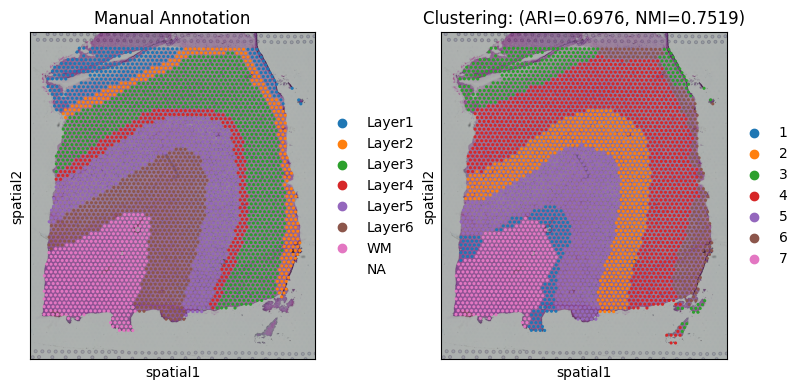

In [27]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1,2,figsize=(4*2, 4))
sc.pl.spatial(final_adata, color='ground_truth', ax=axes[0], show=False)
sc.pl.spatial(final_adata, color='domain', ax=axes[1], show=False)
ARI = final_adata.uns['ARI']
NMI = final_adata.uns['NMI']
axes[0].set_title('Manual Annotation')
axes[1].set_title('Clustering: (ARI=%.4f, NMI=%.4f)' % (ARI, NMI))
plt.tight_layout()
plt.show()

d:\Users\15696\anaconda3\envs\MAEST\lib\site-packages\scanpy\plotting\_tools\scatterplots.py:1251: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
d:\Users\15696\anaconda3\envs\MAEST\lib\site-packages\scanpy\plotting\_tools\scatterplots.py:1251: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))


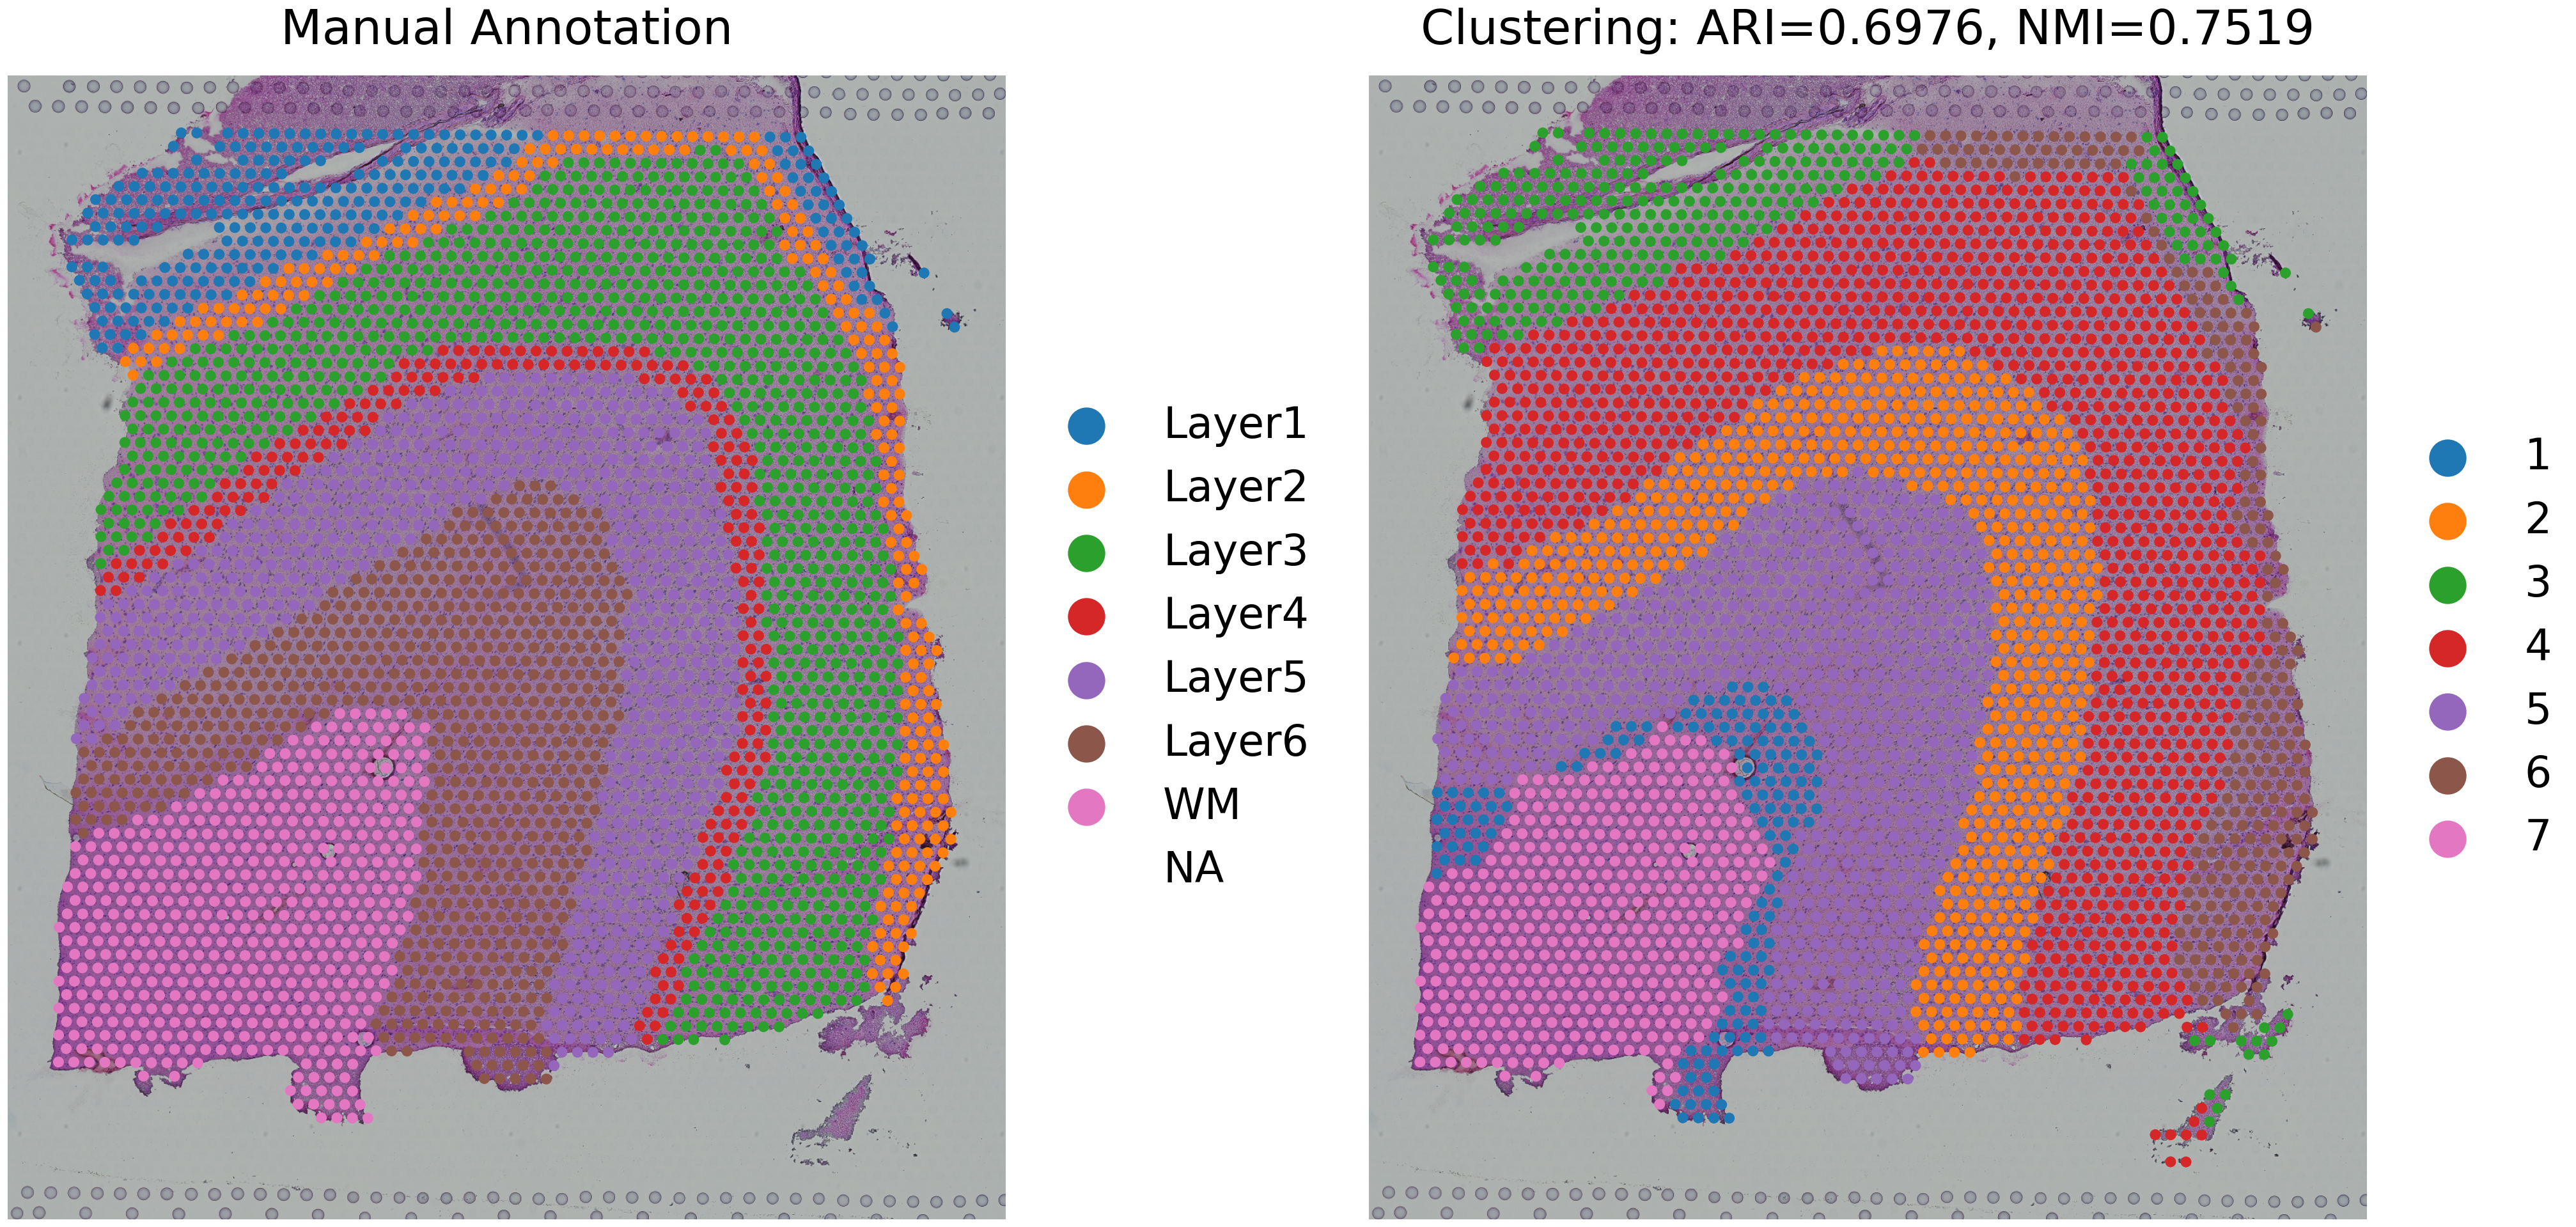

In [28]:
import os
import scanpy as sc
import matplotlib.pyplot as plt
import matplotlib as mpl

os.makedirs("results", exist_ok=True)

mpl.rcParams.update({
    "font.size": 8,
    "axes.titlesize": 9,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.02,
})

DPI = 600

FIG_W = 7.0
FIG_H = 3.4

fig, axes = plt.subplots(1, 2, figsize=(FIG_W, FIG_H), dpi=DPI)

sc.pl.spatial(final_adata, color="ground_truth", ax=axes[0], show=False, title="", frameon=False)
sc.pl.spatial(final_adata, color="domain", ax=axes[1], show=False, title="", frameon=False)

ARI = final_adata.uns["ARI"]
NMI = final_adata.uns["NMI"]

axes[0].set_title("Manual Annotation")
axes[1].set_title("Clustering: ARI=%.4f, NMI=%.4f" % (ARI, NMI))

plt.tight_layout()

plt.show()

d:\Users\15696\anaconda3\envs\MAEST\lib\site-packages\scanpy\plotting\_tools\scatterplots.py:1251: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
d:\Users\15696\anaconda3\envs\MAEST\lib\site-packages\scanpy\plotting\_tools\scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
d:\Users\15696\anaconda3\envs\MAEST\lib\site-packages\scanpy\plotting\_tools\scatterplots.py:1251: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
d:\Users\1569

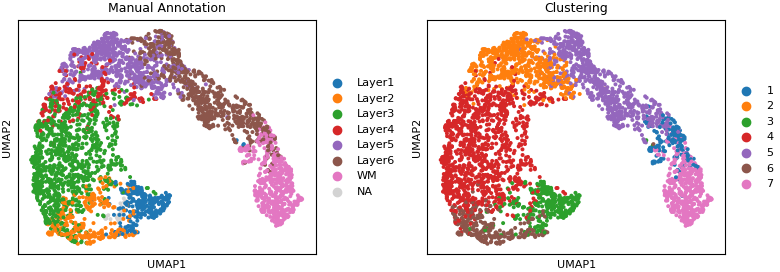

In [30]:

sc.pp.neighbors(final_adata, use_rep='emb', metric='cosine')
sc.tl.umap(final_adata)

fig, axes = plt.subplots(1,2,figsize=(4*2, 3))
sc.pl.umap(final_adata, color='ground_truth', ax=axes[0], show=False)
sc.pl.umap(final_adata, color='domain', ax=axes[1], show=False)
axes[0].set_title('Manual Annotation')
axes[1].set_title('Clustering')

for ax in axes:
    ax.set_aspect(1)

plt.tight_layout()
plt.show()
